# Scientific Programming (MSB1015) Course

# Project Data Overview
Scientific Programming (MSB1015) Course project Data Overview
<b>Project</b>: Brain region-dependent task-specific temporal integration of visual information in mouse visual cortex<br>

This Notebooks gives an overview over the Allen Natural Movies Dataset which stems from the Visual Coding Neuropixels project. In this project, electrophysiological data was gathered by recording brain activity using Neuropixels while the Mice were shown short clips from the Black & White Movie "Touch of Evil" (Zugsmith & Welles, 1958).

Neuropixels Docs: https://allensdk.readthedocs.io/en/latest/visual_coding_neuropixels.html<br>
Allen SDK: https://allensdk.readthedocs.io/en/latest/index.html<br>
Natural Movies Dataset: https://observatory.brain-map.org/visualcoding/stimulus/natural_movies

## Imports

In [4]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import glob, os

from allensdk.brain_observatory.ecephys.ecephys_project_cache import EcephysProjectCache # API for Allen Natural Movies data
from allensdk.core.reference_space_cache import ReferenceSpaceCache

from paths import PROJECT_ROOT, ALLEN_DIR, EXTRACTED_DIR, RESULTS_DIR, MANIFEST

## Paths

Imported from paths.py

## Cache
Manager object sitting between the custom code and Allen's data/servers. Looks up data in the local cache folder, if not present it downloads it from Allen's servers and saves it to disk.

In [14]:
# from_warehouse() pulls from Allen's servers. Alternative:
# EcephysProjectCache.from_s3_cache(cache_dir=DATA_DIR) for the AWS mirror
cache = EcephysProjectCache.from_warehouse(manifest=str(MANIFEST))
print(sorted(ALLEN_DIR.glob("session_*")))  # lists cached session folders

[WindowsPath('C:/Users/Mariu/Desktop/Scientific_Programming_Project/allen_ecephys/session_715093703'), WindowsPath('C:/Users/Mariu/Desktop/Scientific_Programming_Project/allen_ecephys/session_721123822'), WindowsPath('C:/Users/Mariu/Desktop/Scientific_Programming_Project/allen_ecephys/session_732592105'), WindowsPath('C:/Users/Mariu/Desktop/Scientific_Programming_Project/allen_ecephys/session_737581020'), WindowsPath('C:/Users/Mariu/Desktop/Scientific_Programming_Project/allen_ecephys/session_739448407'), WindowsPath('C:/Users/Mariu/Desktop/Scientific_Programming_Project/allen_ecephys/session_742951821'), WindowsPath('C:/Users/Mariu/Desktop/Scientific_Programming_Project/allen_ecephys/session_743475441'), WindowsPath('C:/Users/Mariu/Desktop/Scientific_Programming_Project/allen_ecephys/session_744228101'), WindowsPath('C:/Users/Mariu/Desktop/Scientific_Programming_Project/allen_ecephys/session_746083955'), WindowsPath('C:/Users/Mariu/Desktop/Scientific_Programming_Project/allen_ecephys/

## CCF Ontology
Allen Common Coordinate Framework specifying the brain's 3D voxel space, specifically the brain regions.
Documentation: https://brain-map.org/support/tutorials/intro-to-the-adult-mouse-atlas

In [8]:
# small one-time download of the CCF ontology (structures.json), gets cached
rspc = ReferenceSpaceCache(
    resolution=25,
    reference_space_key="annotation/ccf_2017",
    manifest=str(ALLEN_DIR / "reference_space_manifest.json"),
)

tree = rspc.get_structure_tree(file_name="structures.json")

# creates a map so the acronym can be easily used to index the full name of the region
acr_to_id  = tree.get_id_acronym_map()                 # e.g., {'VISp': 385, ...}
id_to_name = tree.get_name_map()                       # e.g., {385: 'Primary visual area', ...}
acr_to_name = {a: id_to_name[i] for a, i in acr_to_id.items()}

## Constants

The brain areas of the mouse visual cortex that are of interest

In [9]:
VISUAL_CORTEX = ["VISp", "VISl", "VISal", "VISrl", "VISam", "VISpm"]  # the identifiers for the regions of the visual cortex in the Allen Natural Movies dataset

## Metadata Overview

In [12]:
sessions = cache.get_session_table()
probes   = cache.get_probes()
channels = cache.get_channels()
units    = cache.get_units() # includes every sorted neuron across the dataset

print(f"Sessions : {len(sessions)}")
print(f"Probes   : {len(probes)}")
print(f"Channels : {len(channels)}")
print(f"Units    : {len(units)}")

Sessions : 58
Probes   : 332
Channels : 123224
Units    : 40010


## Session Types

Fetches the Sessions and prints their types and count

In [13]:
# Prints the Session types, where "brain_observatory_1.1" is the session type for the Allen Natural Movies dataset
print("Session types:")
print(sessions["session_type"].value_counts(), "\n")

sessions = cache.get_session_table()  # gets session table (metadata for all sessions in the dataset)
session_id = sessions[sessions.session_type == "brain_observatory_1.1"].index[0]  # extracts first session

# load the session to display metadata (first call downloads that session's ~2 GB NWB, then it's cached)
session = cache.get_session_data(session_id)

Session types:
brain_observatory_1.1      32
functional_connectivity    26
Name: session_type, dtype: int64 



Downloading: 100%|██████████| 2.86G/2.86G [01:52<00:00, 25.4MB/s] 
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\hdmf\spec\namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.5.1 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\hdmf\spec\namespace.py:531: UserWarning: Ignoring cached namespace 'core' version 2.2.2 because version 2.5.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


## Session Overview

Gives an overview of the session metadata as well as the stimulus presentation table of the movie

In [15]:
# gets the stimulus table for the first movie
first_movie = session.get_stimulus_table("natural_movie_one")
print(first_movie.columns.tolist()) # prints the columns of the stimulus table for the first movie, which includes 'frame', 'start_time', 'stop_time', and 'stimulus_block'
display(first_movie.head()) # shows the first 5 rows of the stimulus table for the first movie, which includes columns like 'frame', 'start_time', 'stop_time', and 'stimulus_block'

# displays properties of one repeat:
frames_per_repeat = int(first_movie["frame"].max()) + 1         # 900 for movie_one (~30 s @ 30 fps)
n_repeats = int((first_movie["frame"] == 0).sum())              # a repeat = one full 0 → N-1 playback
onsets = first_movie.loc[first_movie["frame"] == 0, "start_time"].to_numpy()
print(f"{n_repeats} repeats | {frames_per_repeat} frames/repeat | "
      f"blocks: {sorted(first_movie['stimulus_block'].unique())} | "
      f"repeat duration ≈ {np.median(np.diff(onsets)):.1f} s | "
      f"frame duration ≈ {(first_movie['stop_time']-first_movie['start_time']).median()*1000:.0f} ms")

['stimulus_block', 'start_time', 'stop_time', 'contrast', 'stimulus_name', 'frame', 'orientation', 'size', 'duration', 'stimulus_condition_id']


,stimulus_block,start_time,stop_time,contrast,stimulus_name,frame,orientation,size,duration,stimulus_condition_id
stimulus_presentation_id,,,,,,,,,,
22000,4.0,2835.861733,2835.895094,1.0,natural_movie_one,0.0,0.0,"[1920.0, 1080.0]",0.033361,3887
22001,4.0,2835.895094,2835.928455,1.0,natural_movie_one,1.0,0.0,"[1920.0, 1080.0]",0.033361,3888
22002,4.0,2835.928455,2835.961816,1.0,natural_movie_one,2.0,0.0,"[1920.0, 1080.0]",0.033361,3889
22003,4.0,2835.961816,2835.995178,1.0,natural_movie_one,3.0,0.0,"[1920.0, 1080.0]",0.033361,3890
22004,4.0,2835.995178,2836.028539,1.0,natural_movie_one,4.0,0.0,"[1920.0, 1080.0]",0.033361,3891


20 repeats | 900 frames/repeat | blocks: [4.0, 12.0] | repeat duration ≈ 30.0 s | frame duration ≈ 33 ms


## Movie Overview
Gives an overview of the movie by displaying a few frames from it.

template shape: (900, 304, 608)


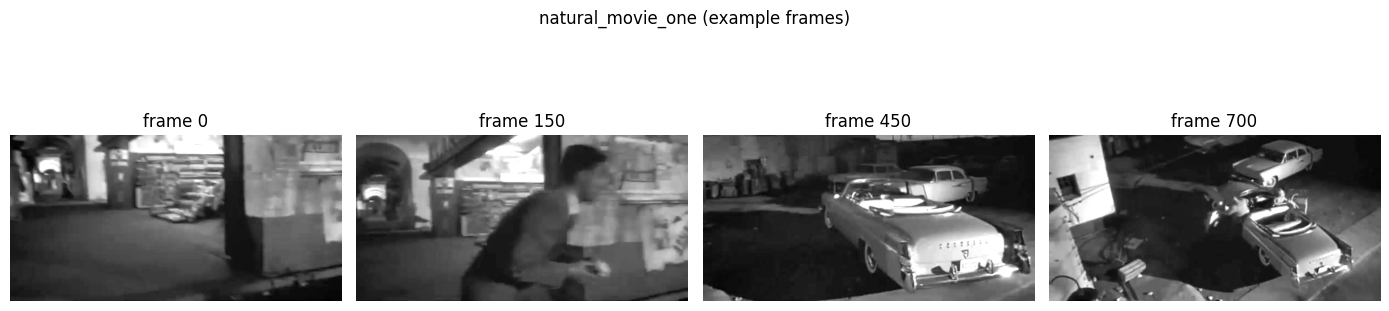

In [ ]:
movie = cache.get_natural_movie_template(1)     # 1 = natural_movie_one, 3 = natural_movie_three
print("template shape:", movie.shape)           # (n_frames, height, width), grayscale

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, fr in zip(axes, [0, 150, 450, 700]):    # displays a few example frames
    ax.imshow(movie[fr], cmap="gray")
    ax.set_title(f"frame {fr}")
    ax.axis("off")

plt.suptitle("natural_movie_one (example frames)")
plt.tight_layout()
plt.show()

## Brain Areas Overview
Gives an overview of the brain areas included in the Allen Natural Movies Dataset, specifically their identifier, unit count and full name

In [17]:
# Prints the amount of units per recorded brain area (brain areas with the 15 most units selected)
counts = units["ecephys_structure_acronym"].value_counts().head(15)
print("Units per recorded structure (top 15):")
for acr, n in counts.items():
    print(f"  {acr:<7} {n:>6}  {acr_to_name.get(acr, '—')}")
    
# Prints the total amount of units in the 6 visual cortical areas (VISp, VISl, VISal, VISrl, VISam, VISpm) 
vis_counts = (units["ecephys_structure_acronym"]
              .value_counts()
              .reindex(VISUAL_CORTEX)          # just the 6 visual areaas
              .fillna(0).astype(int))

print("Units per visual cortical area:")
for acr, n in vis_counts.items():
    print(f"  {acr:<6} {n:>6}  {acr_to_name.get(acr, '')}")

print(f"\n  Total across the 6 areas: {vis_counts.sum()}")

Units per recorded structure (top 15):
  CA1       5878  Field CA1
  grey      3716  Basic cell groups and regions
  VISp      3694  Primary visual area
  VISal     3036  Anterolateral visual area
  VISam     2959  Anteromedial visual area
  VISrl     2567  Rostrolateral visual area
  LP        2492  Lateral posterior nucleus of the thalamus
  VISl      2075  Lateral visual area
  VISpm     1798  posteromedial visual area
  DG        1655  Dentate gyrus
  LGd       1306  Dorsal part of the lateral geniculate complex
  APN       1297  Anterior pretectal nucleus
  VIS        969  Visual areas
  SUB        850  Subiculum
  CA3        815  Field CA3
Units per visual cortical area:
  VISp     3694  Primary visual area
  VISl     2075  Lateral visual area
  VISal    3036  Anterolateral visual area
  VISrl    2567  Rostrolateral visual area
  VISam    2959  Anteromedial visual area
  VISpm    1798  posteromedial visual area

  Total across the 6 areas: 16129


## Plot visual areas

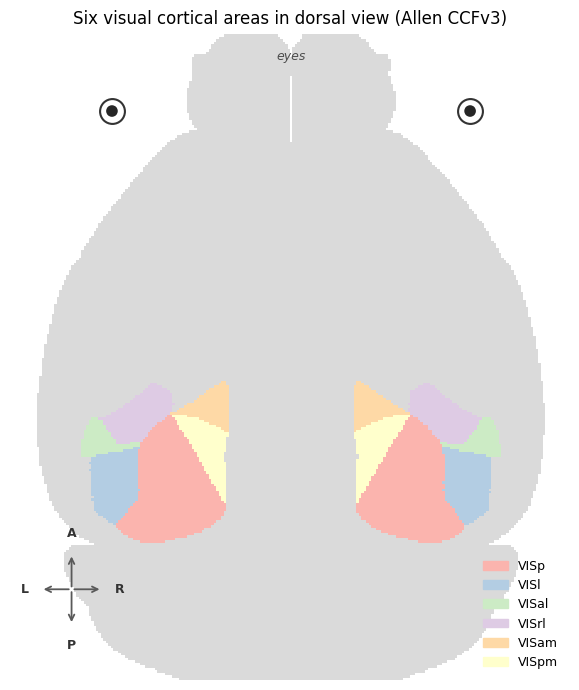

In [ ]:
# Downloads the Allen CCFv3 annotation volume (3D) and structure tree (ontology) for plotting with higher resolution
rspc = ReferenceSpaceCache(
    resolution=50,
    reference_space_key="annotation/ccf_2017",
    manifest=str(ALLEN_DIR / "refspace_manifest.json"),
)

rsp  = rspc.get_reference_space()  # downloads the reference-space annotation volume which is a 3D grid with voxel values identifying brain structures
tree = rspc.get_structure_tree()   # loads the structure ontology (includes region IDs, acronyms, names and their hierarchy)
acr_to_id = tree.get_id_acronym_map()  # returns mapping of structure ID -> acronym

# Dorsal projection: annotation axes are (AP, DV, ML), flattens the DV axis.
brain2d = rsp.annotation.any(axis=1)    # brain silhouette (AP × ML)
label = np.full(brain2d.shape, np.nan)
label[brain2d] = 0                      # 0 = brain (grey)

for k, acr in enumerate(VISUAL_CORTEX, start=1):
    area_mask = rsp.make_structure_mask([acr_to_id[acr]])  # 3D, includes cortical layers
    label[area_mask.any(axis=1)] = k                       # paints its top-down footprint

pastel = plt.get_cmap("Pastel1")  # 9 pastel swatches
area_colors = {acr: pastel(i) for i, acr in enumerate(VISUAL_CORTEX)}

colors = ["#DADADA"] + [area_colors[a] for a in VISUAL_CORTEX]  # 0 as grey for other brain areas, 1 to 6 for visual areas
cmap = ListedColormap(colors)
cmap.set_bad(alpha=0)
norm = BoundaryNorm(np.arange(-0.5, len(colors) + 0.5), cmap.N)

# Plotting
fig, ax = plt.subplots(figsize=(6, 7))
ax.imshow(np.ma.masked_invalid(label), cmap=cmap, norm=norm,
          origin="upper", interpolation="nearest")

ax.set_title("Six visual cortical areas in dorsal view (Allen CCFv3)")
ax.axis("off")
ax.legend(handles=[Patch(color=area_colors[a], label=a) for a in VISUAL_CORTEX],
          loc="lower right", frameon=False, fontsize=9)

cx, cy, r = 0.11, 0.14, 0.055          # axes-fraction center + arm length
for dx, dy, lab, ha, va in [(0,  r, "A", "center", "bottom"),   # anterior  = down
                            (0, -r, "P", "center", "top"),      # posterior = up
                            (r,  0, "R", "left",   "center"),   # right hemisphere
                            (-r, 0, "L", "right",  "center")]:  # left hemisphere
    ax.annotate("", xy=(cx + dx, cy + dy), xytext=(cx, cy), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="->", lw=1.3, color="0.35"))
    ax.text(cx + dx * 1.4, cy + dy * 1.4, lab, transform=ax.transAxes,
            ha=ha, va=va, fontsize=9, fontweight="bold", color="0.2")

# Eye markers: anterior & lateral
nAP, nML = label.shape
eye_y = 0.12 * nAP                          # near the anterior end (top, since origin='upper')
for eye_x in (0.18 * nML, 0.82 * nML):      # left & right, lateral to the brain
    ax.scatter(eye_x, eye_y, s=320, facecolor="white", edgecolor="0.2",
               linewidth=1.5, zorder=5, clip_on=False)          # sclera
    ax.scatter(eye_x, eye_y, s=70,  facecolor="0.15", edgecolor="none",
               zorder=6, clip_on=False)                         # pupil
ax.text(0.5 * nML, 0.045 * nAP, "eyes", ha="center", va="bottom",
        fontsize=9, style="italic", color="0.3")

plt.tight_layout()
plt.show()